In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Задача 1. Эффективная и неэффективная оценки интенсивности

Пусть $X_i$ — число обращений в поддержку за один час, причём

$$
X_1,\ldots,X_n\overset{\mathrm{iid}}{\sim}\operatorname{Pois}(\lambda),
$$

где $\lambda>0$ — неизвестное среднее число обращений за час.

Для одного наблюдения

$$
\mathbb{P}_\lambda(X=x)=\frac{\lambda^x e^{-\lambda}}{x!},\qquad x=0,1,2,\ldots
$$

Рассмотрим две оценки одного и того же параметра:

$$
\widehat\lambda_1=\overline X,
\qquad
\widehat\lambda_2=X_1.
$$

Нужно:

1. Найди score $U_\lambda(X)$.
2. Найди $I_1(\lambda)$ и $I_n(\lambda)$.
3. Выпиши границу Рао–Крамера.
4. Проверь несмещённость обеих оценок.
5. Найди дисперсии $\widehat\lambda_1$ и $\widehat\lambda_2$.
6. Определи, какая оценка эффективна.
7. Найди коэффициенты эффективности обеих оценок.
8. Проведи расчёты при $\lambda=9$, $n=36$.

**Решение**

## Пункт 1. Score

Логарифм функции вероятности одного наблюдения:

$$
\log \mathbb{P}_\lambda(X=x)=x\log\lambda-\lambda-\log(x!).
$$

Дифференцируем по $\lambda$:

$$
\frac{\partial}{\partial\lambda}(x\log\lambda)=\frac{x}{\lambda},
\qquad
\frac{\partial}{\partial\lambda}(-\lambda)=-1.
$$

Слагаемое $-\log(x!)$ от $\lambda$ не зависит.

Поэтому

$$
\boxed{U_\lambda(X)=\frac{X}{\lambda}-1=\frac{X-\lambda}{\lambda}}.
$$

## Пункт 2. Информация Фишера

По определению

$$
I_1(\lambda)=\mathbb{E}[U_\lambda(X)^2].
$$

Подставляем score:

$$
I_1(\lambda)=\mathbb{E}\left[\frac{(X-\lambda)^2}{\lambda^2}\right]
=\frac{\mathbb{E}[(X-\lambda)^2]}{\lambda^2}.
$$

Для распределения Пуассона

$$
\mathbb{E}[X]=\lambda,
\qquad
\operatorname{Var}(X)=\lambda.
$$

Следовательно,

$$
\mathbb{E}[(X-\lambda)^2]=\lambda,
$$

и

$$
\boxed{I_1(\lambda)=\frac{1}{\lambda}}.
$$

Во всей выборке

$$
\boxed{I_n(\lambda)=\frac{n}{\lambda}}.
$$

## Пункт 3. Граница Рао–Крамера

Для любой несмещённой оценки $\lambda$:

$$
\operatorname{Var}(\widehat\lambda)\geq\frac{1}{I_n(\lambda)}.
$$

Значит,

$$
\boxed{\operatorname{Var}(\widehat\lambda)\geq\frac{\lambda}{n}}.
$$

## Пункт 4. Несмещённость оценок

Для первой оценки

$$
\mathbb{E}[\widehat\lambda_1]
=\mathbb{E}[\overline X]
=\lambda.
$$

Для второй оценки

$$
\mathbb{E}[\widehat\lambda_2]
=\mathbb{E}[X_1]
=\lambda.
$$

Обе оценки несмещённые.

Важно: **несмещённость сама по себе ещё не означает эффективность**.

## Пункт 5. Дисперсии оценок

Для среднего по всей выборке

$$
\operatorname{Var}(\widehat\lambda_1)
=\operatorname{Var}(\overline X)
=\frac{\lambda}{n}.
$$

Вторая оценка использует только первое наблюдение:

$$
\operatorname{Var}(\widehat\lambda_2)
=\operatorname{Var}(X_1)
=\lambda.
$$

При $n>1$ первая оценка имеет меньшую дисперсию в $n$ раз.

## Пункт 6. Какая оценка эффективна

Граница Рао–Крамера равна

$$
\frac{\lambda}{n}.
$$

Для $\widehat\lambda_1$:

$$
\operatorname{Var}(\widehat\lambda_1)=\frac{\lambda}{n}.
$$

Она достигает границы, значит

$$
\boxed{\widehat\lambda_1=\overline X\text{ эффективна}.}
$$

Для $\widehat\lambda_2$ при $n>1$:

$$
\operatorname{Var}(\widehat\lambda_2)=\lambda>\frac{\lambda}{n}.
$$

Поэтому

$$
\boxed{\widehat\lambda_2=X_1\text{ неэффективна}.}
$$

## Пункт 7. Коэффициент эффективности

Используем

$$
\operatorname{Eff}(\widehat\lambda)
=\frac{1/I_n(\lambda)}{\operatorname{Var}(\widehat\lambda)}.
$$

Для $\widehat\lambda_1$:

$$
\operatorname{Eff}(\widehat\lambda_1)
=\frac{\lambda/n}{\lambda/n}=1.
$$

Для $\widehat\lambda_2$:

$$
\operatorname{Eff}(\widehat\lambda_2)
=\frac{\lambda/n}{\lambda}=\frac{1}{n}.
$$

То есть вторая оценка остаётся несмещённой, но использует информацию из выборки крайне неэффективно.

## Пункт 8. Проверка на числах

Пусть $\lambda=9$, $n=36$.

Информация Фишера во всей выборке:

$$
I_n(\lambda)=\frac{36}{9}=4.
$$

Граница Рао–Крамера:

$$
\frac{1}{I_n(\lambda)}=\frac{1}{4}=0.25.
$$

Для среднего:

$$
\operatorname{Var}(\widehat\lambda_1)=\frac{9}{36}=0.25,
\qquad
\operatorname{Eff}(\widehat\lambda_1)=1.
$$

Для одного наблюдения:

$$
\operatorname{Var}(\widehat\lambda_2)=9,
\qquad
\operatorname{Eff}(\widehat\lambda_2)=\frac{1}{36}.
$$

Обе оценки в среднем попадают в $\lambda$, но их точность при фиксированном $n$ очень разная.

# Задача 2. Оценка дисперсии. Смещённость и несмещённость

Продемонстрируем свойства состоятельности и несмещённости с помощью симуляций для различных $n$.

Создадим нормальное распределение с параметрами $\mu = 650$ и $\sigma = 300$.

In [ ]:
# Параметры нормального распределения
mu, sd = 650, 300

Затем создадим миллион наблюдений и рассчитаем среднее из этого миллиона наблюдений.

Рассчитаем эмпирическое среднее и запишем его в переменную *real_mean*.

In [ ]:
# Создаем генеральную совокупность из 1 миллиона наблюдений
user_spend_gp = np.random.normal(mu, sd, 10**6)
real_mean = np.mean(user_spend_gp)
print(f"Среднее = {real_mean:.2f}")

Среднее = 650.03


Создаём пустые списки для хранения оценок смещённой и несмещённой дисперсии.

In [ ]:
biased_vars, unbiased_vars = [], []

Для каждого размера выборки рассчитаем значения смещённой и несмещённой дисперсии.

Будем использовать параметр *ddof* (degrees of freedom) функции *var* из *numpy*.

 - ddof $= 0$  - выборочная дисперсия (смещённая);
 - ddof $= 1$ - выборочная дисперсия (несмещённая);

In [ ]:
n_trials = 50

for n in range(100, 10000, 100):
  # на одной итерации получаем n_trials оценок
  # при семплировании из генсовокупности n наблюдений
  rand_smpl = np.random.choice(user_spend_gp, size=(n, n_trials), replace=True)
  biased_var = np.var(rand_smpl, ddof=0, axis=0)
  unbiased_var = np.var(rand_smpl, ddof=1, axis=0)

  # каждый результат расчёта прикрепляем к соответствующему списку
  biased_vars.append(biased_var)
  unbiased_vars.append(unbiased_var)

Приведём векторы с дисперсиями к формату *numpy-array*.

In [ ]:
biased_vars, unbiased_vars = np.array(biased_vars), np.array(unbiased_vars)

In [ ]:
biased_vars[0]

array([ 98523.25445774,  60311.97124936, 106876.50116182,  92072.95511409,
        77060.80809451,  84741.61378735, 114387.67022429,  91466.84901267,
        77160.62748475,  86951.0613629 ,  80837.23011054,  90179.30821951,
        94647.97600076,  81659.30562146,  77879.95932959, 104948.42440345,
        83154.95967085,  84041.16719719,  74940.97961575,  66960.94913885,
       106142.01391767, 103179.2608315 ,  87456.24582488,  83033.19203301,
        84429.51254398,  89041.24798597,  84045.9880624 ,  87792.98607339,
       108796.95114743, 101671.39812067,  82231.84421997, 107448.08176206,
        81688.31963287,  81198.95941534, 107221.72318525, 108168.87201207,
       110037.4061906 ,  90090.61526302, 101416.61924059,  80481.05424879,
        72082.05770648,  92226.72302281,  99554.72001211,  89013.04012814,
       105335.00931734,  87046.54396754,  99115.77697746, 110225.67337812,
       112614.70097676, 100120.17616948])

In [ ]:
unbiased_vars[0]

array([ 99518.4388462 ,  60921.18308016, 107956.06177962,  93002.98496372,
        77839.20009547,  85597.58968419, 115543.10123666,  92390.75657845,
        77940.02776238,  87829.35491202,  81653.76778842,  91090.21032274,
        95604.01616238,  82484.14709238,  78666.62558545, 106008.50949843,
        83994.90875843,  84890.06787594,  75697.95920783,  67637.32236248,
       107214.15547239, 104221.47558738,  88339.64224736,  83871.91114446,
        85282.33590301,  89940.65453128,  84894.93743677,  88679.78391252,
       109895.91024993, 102698.38194007,  83062.46890906, 108533.41592127,
        82513.45417462,  82019.15092458, 108304.77089419, 109261.48688087,
       111148.89514202,  91000.6214778 , 102441.02953595,  81293.99419069,
        72810.15929948,  93158.30608364, 100560.32324455,  89912.1617456 ,
       106398.99931045,  87925.80198742, 100116.94644188, 111339.0640183 ,
       113752.22320885, 101131.49108028])

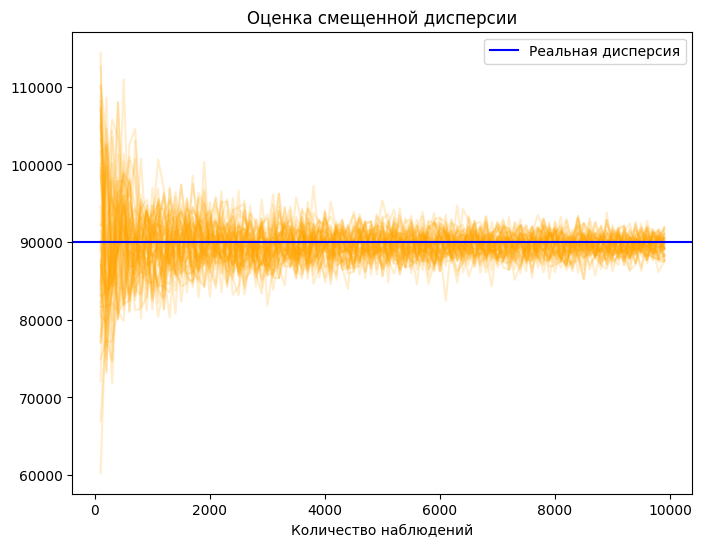

In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(range(100, 10000, 100), biased_vars, color='orange', alpha=0.2)
plt.axhline(sd**2, color='blue', label='Реальная дисперсия')
plt.title('Оценка смещенной дисперсии')
plt.xlabel('Количество наблюдений')
plt.legend()
plt.show()

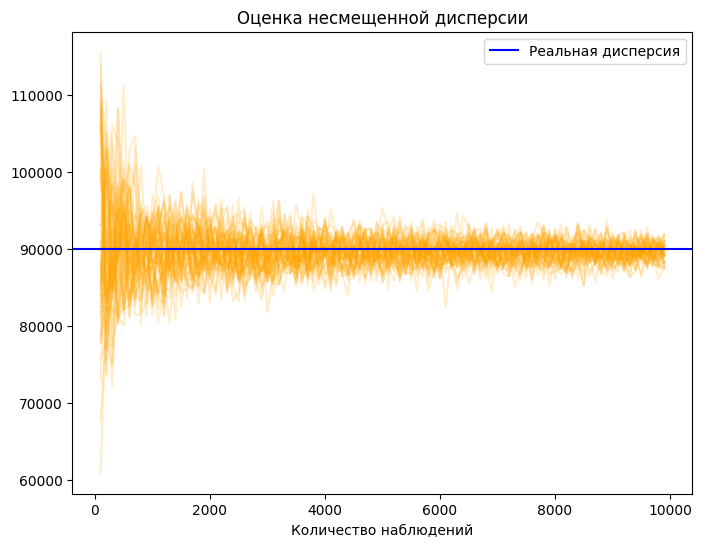

In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(range(100, 10000, 100), unbiased_vars, color='orange', alpha=0.2)
plt.axhline(sd**2, color='blue', label='Реальная дисперсия')
plt.title('Оценка несмещенной дисперсии')
plt.xlabel('Количество наблюдений')
plt.legend()
plt.show()

**Вывод**

При больших $n$ различие между оценками становится небольшим

При малых $n$ смещение хорошо заметно. По мере роста $n$ множитель $(n-1)/n$ приближается к единице, поэтому разница между двумя вариантами уменьшается.

Это хороший пример различия между **свойством при фиксированном $n$** и **асимптотическим поведением**.

Также следует отметить, что обе оценки состоятельны.

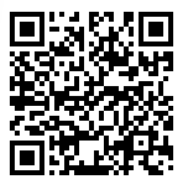